# Customer Churn Predictor: an ANN + a web app
Predict whether a bank customer will **leave the bank** (churn) using an Artificial Neural Network built with Keras, then use it in a **Streamlit** web app.

**Dataset:** `Churn_Modelling.csv` (10,000 customers, target column `Exited`: 1 = left, 0 = stayed)
**How to run:** run the cells from top to bottom. In Google Colab, upload `Churn_Modelling.csv` when Step 0 asks for it. The last part of Step 9 starts the Streamlit app from Colab.

| File | What it is |
|---|---|
| `train.ipynb` | this notebook (Steps 0 to 9) |
| `app.py` | the Streamlit app (also written by the Step 9 cell) |
| `model.keras`, `preprocessor.pkl` | the trained ANN and the fitted preprocessor (Step 8) |

## Step 0: Setup
Install the libraries, check TensorFlow works and that the CSV is in the folder.

In [1]:
# Step 0: install the libraries (safe to run again; Colab already has most of them)
%pip install -q tensorflow pandas scikit-learn joblib streamlit matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import tensorflow as tf

# If you run this in Google Colab, upload Churn_Modelling.csv when asked
if not os.path.exists("Churn_Modelling.csv"):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError("Put Churn_Modelling.csv in the same folder as this notebook")

print("TensorFlow version:", tf.__version__)
print("CSV found:", os.path.exists("Churn_Modelling.csv"))
print("Files in this folder:", sorted(os.listdir(".")))

TensorFlow version: 2.21.0
CSV found: True
Files in this folder: ['Churn_Modelling.csv', 'pass1.ipynb']


**My understanding:** I installed tensorflow (builds and trains the neural network), pandas (keeps the data in tables), scikit-learn (splitting, encoding, scaling and the evaluation numbers), joblib (saves the preprocessor to a file), matplotlib (draws the loss plot) and streamlit (turns the model into a web app). Importing TensorFlow and printing its version worked, and the CSV is in the folder, so the setup is ready.

## Step 1: Load the data
Import the libraries, set a random seed, read the CSV and look at it.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from tensorflow import keras
from tensorflow.keras import layers

# Random seed so the results are the same every time I run the notebook
SEED = 42
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

# Read the CSV into a DataFrame and look at it
df = pd.read_csv("Churn_Modelling.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


**My understanding:** A DataFrame is a table: each row is one bank customer and each column is one fact about that customer, like age, balance or country. This table has 10,000 rows and 14 columns, and the last column, `Exited`, is the answer I want to predict. I also set a random seed (42) so the random parts give the same result every time I run it.

## Step 2: Explore and clean
Check missing values and data types, count stayed vs left, drop the 3 ID columns.

In [4]:
# Missing values and data types
df.info()
print("\nMissing values in total:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# How many customers stayed (0) and how many left (1)?
counts = df["Exited"].value_counts()
print("\nStayed (0):", counts[0], "| Left (1):", counts[1])
print("Churn rate:", round(df["Exited"].mean() * 100, 1), "%")
print("A lazy model that always says 'stays' would be", round(counts[0] / len(df) * 100, 1), "% accurate")

# Drop the 3 columns that do not help prediction
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
print("\nShape after dropping them:", df.shape)
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB

Missing values in total: 0
Duplicate rows: 0

Stayed (0): 7963 | Left (1): 2037
Churn rate: 20.4 %
A lazy mo

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


**My understanding:** RowNumber, CustomerId and Surname are only labels and do not make a customer leave, so I dropped them so the model cannot learn from meaningless things. 7,963 customers stayed and 2,037 left (about 20% left), so a lazy model that always says "stays" is already 79.6% accurate. My ANN has to beat that, and accuracy alone will not tell the whole story because of this imbalance.

## Step 3: Split into train and test
X = inputs, y = `Exited`. 80% train / 20% test, stratified.

In [5]:
# X = the inputs, y = the answer we want to predict
X = df.drop(columns=["Exited"])
y = df["Exited"]

# 80% train / 20% test; stratify keeps the same churn share in both parts
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Churn share in train:", round(y_train.mean() * 100, 2), "% | in test:", round(y_test.mean() * 100, 2), "%")

X_train: (8000, 10) | X_test: (2000, 10)
Churn share in train: 20.38 % | in test: 20.35 %


**My understanding:** I split the data into 8,000 training rows and 2,000 test rows. The test set is like an exam paper the model never saw while studying, so it shows how the model would do on new customers. `stratify` keeps the share of leavers the same in both parts (about 20.4% in each).

## Step 4: Preprocess (One-Hot Encoding + StandardScaler)
Encode the text columns, scale the number columns, combine both in one `ColumnTransformer`.

In [6]:
# Two kinds of columns need different treatment
categorical_cols = ["Geography", "Gender"]                                   # words -> One-Hot Encoding
numeric_cols = [c for c in X.columns if c not in categorical_cols]           # numbers -> StandardScaler
print("Numeric columns:", numeric_cols)

# Combine both treatments in ONE preprocessor
preprocessor = ColumnTransformer(transformers=[
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
    ("num", StandardScaler(), numeric_cols),
])

# Golden rule: fit_transform on TRAIN only, then only transform on TEST
X_train_p = preprocessor.fit_transform(X_train).astype("float32")
X_test_p = preprocessor.transform(X_test).astype("float32")

print("Processed train:", X_train_p.shape, "| processed test:", X_test_p.shape)
print("Column names now:", list(preprocessor.get_feature_names_out()))
print("Mean of the scaled numeric train columns (should be ~0):", X_train_p[:, 5:].mean().round(3))

Numeric columns: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Processed train: (8000, 13) | processed test: (2000, 13)
Column names now: ['cat__Geography_France', 'cat__Geography_Germany', 'cat__Geography_Spain', 'cat__Gender_Female', 'cat__Gender_Male', 'num__CreditScore', 'num__Age', 'num__Tenure', 'num__Balance', 'num__NumOfProducts', 'num__HasCrCard', 'num__IsActiveMember', 'num__EstimatedSalary']
Mean of the scaled numeric train columns (should be ~0): 0.0


**My understanding:** A network can only do maths on numbers, so the words (France/Germany/Spain and Female/Male) become 0/1 columns with One-Hot Encoding, which gives 13 columns (5 from words + 8 numeric). Scaling puts Balance (up to about 250,000) and Tenure (up to 10) on the same scale, otherwise the big numbers would dominate the learning. I fitted the preprocessor on the training data only, because fitting on the test data would let information from the exam leak into the training.

## Step 5: Build the ANN (Keras)
13 inputs, hidden layers of 16 and 8 neurons (ReLU), 1 output neuron (Sigmoid).

In [7]:
n_features = X_train_p.shape[1]          # 13 columns go in
keras.utils.set_random_seed(SEED)       # same starting weights every time

model = keras.Sequential([
    keras.Input(shape=(n_features,)),            # input: one neuron per feature
    layers.Dense(16, activation="relu"),         # hidden layer 1
    layers.Dense(8, activation="relu"),          # hidden layer 2
    layers.Dense(1, activation="sigmoid"),       # output: probability of leaving
])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 369 (1.44 KB)

 Trainable params: 369 (1.44 KB)

 Non-trainable params: 0 (0.00 B)

**My understanding:** ReLU keeps positive values and turns negative values into 0, which lets the layers learn patterns that are not just straight lines. Sigmoid squeezes the final number into 0 to 1, so it can be read as the probability of leaving. The output has exactly 1 neuron because the question is yes/no, and one probability is enough (probability of staying = 1 minus it). (Keras only lists the 3 Dense layers in the summary; the 13 inputs are the starting point.)

## Step 6: Train the model
50 epochs, batch size 32, 20% validation split, EarlyStopping on validation loss (patience 5), then plot the loss.

Epoch 1/50


200/200 - 1s - 7ms/step - accuracy: 0.7769 - loss: 0.5166 - val_accuracy: 0.8031 - val_loss: 0.4485


Epoch 2/50


200/200 - 0s - 2ms/step - accuracy: 0.8056 - loss: 0.4345 - val_accuracy: 0.8250 - val_loss: 0.4113


Epoch 3/50


200/200 - 0s - 2ms/step - accuracy: 0.8228 - loss: 0.4062 - val_accuracy: 0.8400 - val_loss: 0.3912


... (91 outputs left out)

200/200 - 1s - 3ms/step - accuracy: 0.8627 - loss: 0.3281 - val_accuracy: 0.8750 - val_loss: 0.3244


Epoch 50/50


200/200 - 0s - 2ms/step - accuracy: 0.8625 - loss: 0.3279 - val_accuracy: 0.8750 - val_loss: 0.3242


Training stopped after 50 epochs


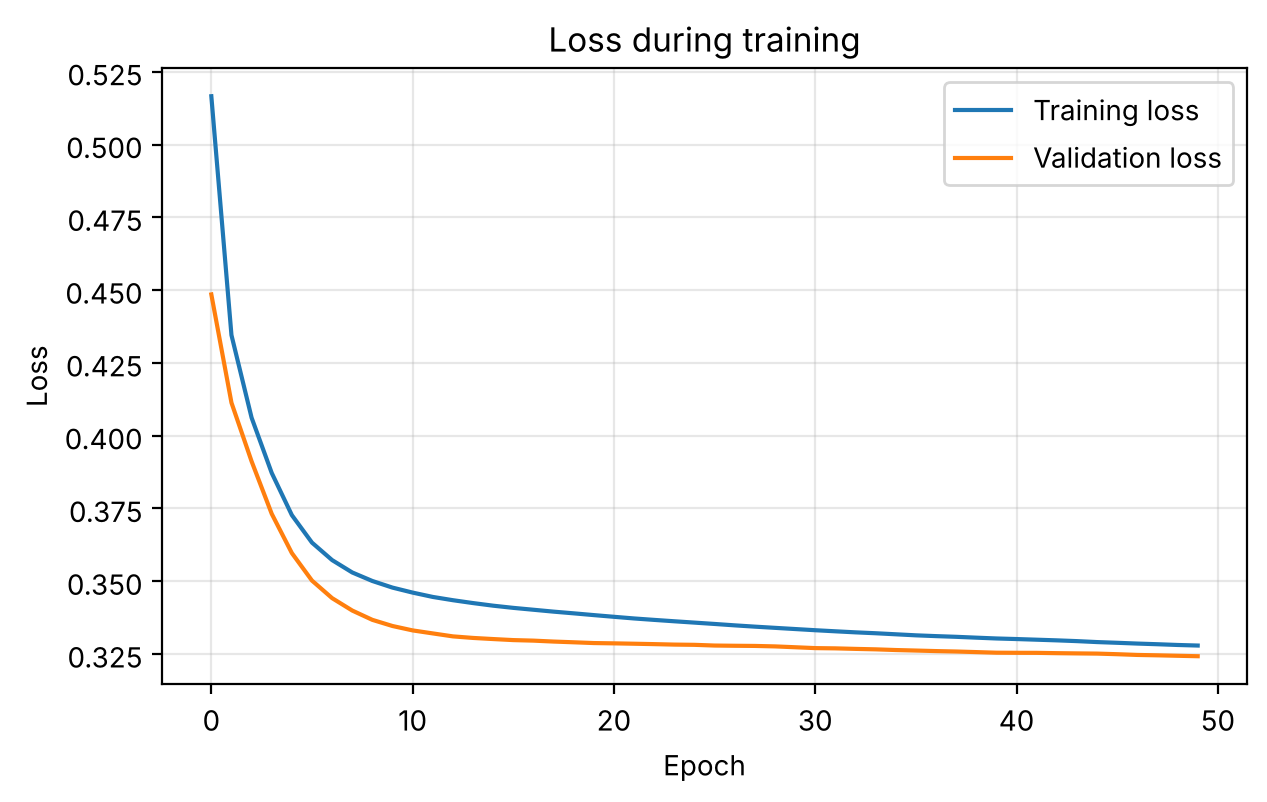

In [8]:
# Stop training when the validation loss has not improved for 5 epochs, and keep the best weights
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history = model.fit(
    X_train_p, y_train,
    validation_split=0.2,     # 20% of the training rows are used to check progress
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=2,
)
print("Training stopped after", len(history.history["loss"]), "epochs")

# Plot training loss and validation loss on the same graph
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss during training")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("loss_plot.png", dpi=120, bbox_inches="tight")
plt.show()

**My understanding:** An epoch is one full pass over all the training data, and a batch is a small group of 32 customers after which the model updates its weights. Both loss lines go down together and stay close to each other, so the model is learning and is not overfitting. EarlyStopping did not stop it early: the validation loss was still improving very slightly at epoch 50, so it ran all 50 epochs.

## Step 7: Evaluate on the test set
Accuracy, confusion matrix and classification report, with a 0.5 threshold.

Test accuracy: 0.8595

Confusion matrix (rows = real, columns = predicted):
[[1526   67]
 [ 214  193]]

Stayed and predicted stay (TN): 1526 | Stayed but predicted leave (FP): 67
Left but predicted stay (FN): 214   | Left and predicted leave (TP): 193

Classification report:
              precision    recall  f1-score   support

  Stayed (0)       0.88      0.96      0.92      1593
    Left (1)       0.74      0.47      0.58       407

    accuracy                           0.86      2000
   macro avg       0.81      0.72      0.75      2000
weighted avg       0.85      0.86      0.85      2000



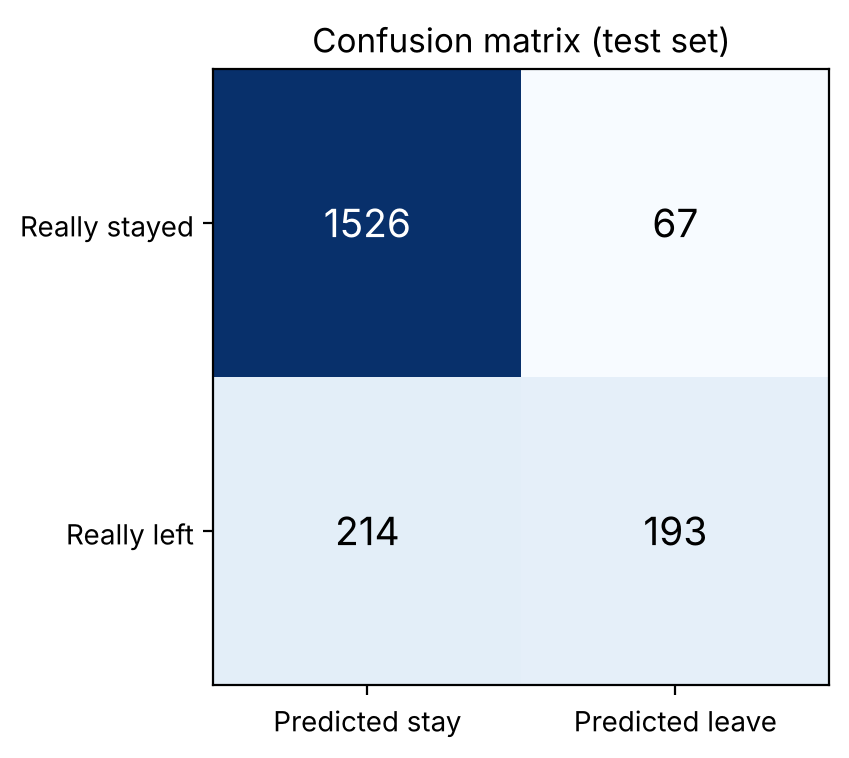

In [9]:
# Probabilities -> 0/1 predictions with a 0.5 threshold
y_prob = model.predict(X_test_p, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion matrix (rows = real, columns = predicted):")
print(cm)
tn, fp, fn, tp = cm.ravel()
print(f"\nStayed and predicted stay (TN): {tn} | Stayed but predicted leave (FP): {fp}")
print(f"Left but predicted stay (FN): {fn}   | Left and predicted leave (TP): {tp}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Stayed (0)", "Left (1)"]))

# Picture of the confusion matrix
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], ["Predicted stay", "Predicted leave"])
ax.set_yticks([0, 1], ["Really stayed", "Really left"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_title("Confusion matrix (test set)")
plt.savefig("confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

**My understanding:** Out of 2,000 test customers, the model correctly said STAY for 1,526 and correctly said LEAVE for 193; it wrongly flagged 67 who actually stayed and missed 214 who really left. Accuracy is 85.95%, better than the 79.6% lazy guess, but recall for class 1 is only 0.47, so it finds fewer than half of the leavers. I think this is because only about 1 in 5 customers leave, so the model learns to play safe and say STAY; a bank cares because every missed leaver is a customer it could have tried to keep.

## Step 8: Save the model and the preprocessor
`model.keras` and `preprocessor.pkl`, then a sanity check with one test customer.

In [10]:
# Save the trained model and the fitted preprocessor
model.save("model.keras")
joblib.dump(preprocessor, "preprocessor.pkl")
print("Saved:", [f for f in ["model.keras", "preprocessor.pkl"] if os.path.exists(f)])

# Sanity check: load both files back, then predict ONE customer from the test set
loaded_model = keras.models.load_model("model.keras")
loaded_preprocessor = joblib.load("preprocessor.pkl")

one_customer = X_test.iloc[[0]]
print("\nThe customer:")
print(one_customer.T)
prob = float(loaded_model.predict(loaded_preprocessor.transform(one_customer), verbose=0)[0][0])
print(f"\nPredicted churn probability: {prob:.3f} -> predicted {'LEAVE' if prob >= 0.5 else 'STAY'}")
print("Real answer:", "LEAVE" if y_test.iloc[0] == 1 else "STAY")

# Extra check: the reloaded model gives the same answers as the original on the whole test set
same = np.allclose(loaded_model.predict(loaded_preprocessor.transform(X_test), verbose=0).ravel(), y_prob, atol=1e-5)
print("Reloaded model gives the same predictions on all 2000 test customers:", same)

# In Colab: download both files so they can be put next to app.py
try:
    from google.colab import files
    files.download("model.keras")
    files.download("preprocessor.pkl")
except ImportError:
    print("(Not in Colab, so no download needed: the files are in this folder.)")

Saved: ['model.keras', 'preprocessor.pkl']

The customer:
                     5702
CreditScore           585
Geography          France
Gender               Male
Age                    36
Tenure                  7
Balance               0.0
NumOfProducts           2
HasCrCard               1
IsActiveMember          0
EstimatedSalary  94283.09

Predicted churn probability: 0.018 -> predicted STAY
Real answer: STAY


Reloaded model gives the same predictions on all 2000 test customers: True
(Not in Colab, so no download needed: the files are in this folder.)


**My understanding:** The model only understands data that has been encoded and scaled exactly like the training data, and the preprocessor is what remembers how (the training averages, spreads and the list of countries). So I saved both `model.keras` and `preprocessor.pkl`. Without the preprocessor the app would crash on words like "France" or give wrong answers because the numbers would be on the wrong scale.

## Step 9: Build the app (Streamlit)
The cell below writes `app.py`. It loads the two saved files once, asks for every feature, and shows the churn probability and a STAY / LEAVE verdict.

In [11]:
%%writefile app.py
"""Bank customer churn predictor (Streamlit app).

Run it with:   streamlit run app.py
It needs model.keras and preprocessor.pkl in the SAME folder as this file.
"""
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st
from tensorflow import keras

HERE = Path(__file__).parent  # the folder where app.py lives

st.set_page_config(page_title="Churn Predictor", page_icon="🏦")


@st.cache_resource
def load_files():
    """Load the trained model and the preprocessor ONE time, when the app starts."""
    model = keras.models.load_model(HERE / "model.keras")
    preprocessor = joblib.load(HERE / "preprocessor.pkl")
    return model, preprocessor


model, preprocessor = load_files()

st.title("🏦 Bank Customer Churn Predictor")
st.write("Fill in the customer's details, then click **Predict** to see how likely "
         "this customer is to leave the bank.")

# ---------- 1. Inputs (one for every feature the model was trained on) ----------
left, right = st.columns(2)
with left:
    geography = st.selectbox("Geography", ["France", "Germany", "Spain"])
    gender = st.selectbox("Gender", ["Male", "Female"])
    age = st.slider("Age", 18, 92, 38)
    credit_score = st.number_input("Credit score", min_value=300, max_value=900, value=650, step=10)
    tenure = st.slider("Tenure (years with the bank)", 0, 10, 5)
with right:
    balance = st.number_input("Balance", min_value=0.0, max_value=260000.0, value=76000.0, step=1000.0)
    num_products = st.selectbox("Number of products", [1, 2, 3, 4])
    has_card = st.radio("Has a credit card?", ["Yes", "No"], horizontal=True)
    is_active = st.radio("Is an active member?", ["Yes", "No"], horizontal=True)
    salary = st.number_input("Estimated salary", min_value=0.0, max_value=200000.0, value=100000.0, step=1000.0)

# Bonus: the user can move the decision threshold (default 0.5, as in the manual)
threshold = st.slider("Decision threshold", 0.30, 0.70, 0.50, step=0.01,
                      help="The customer is called 'likely to LEAVE' when the churn probability "
                           "is at or above this value. Lower = catches more leavers, but more false alarms.")

# ---------- 2. Predict ----------
inputs = (geography, gender, age, credit_score, tenure, balance,
          num_products, has_card, is_active, salary)

if st.button("Predict", type="primary"):
    # Build a ONE-row table with the SAME column names the model was trained on
    customer = pd.DataFrame([{
        "CreditScore": credit_score,
        "Geography": geography,
        "Gender": gender,
        "Age": age,
        "Tenure": tenure,
        "Balance": balance,
        "NumOfProducts": num_products,
        "HasCrCard": 1 if has_card == "Yes" else 0,          # Yes/No back to 1/0
        "IsActiveMember": 1 if is_active == "Yes" else 0,
        "EstimatedSalary": salary,
    }])
    X_new = preprocessor.transform(customer)                   # same encoding + scaling as training
    probability = float(model.predict(X_new, verbose=0)[0][0])
    st.session_state["result"] = {"probability": probability, "inputs": inputs}

# ---------- 3. Show the result ----------
result = st.session_state.get("result")
if result is not None:
    if result["inputs"] != inputs:
        st.warning("You changed the details. Click **Predict** again to update the result.")
    else:
        probability = result["probability"]
        st.metric("Churn probability", f"{probability * 100:.1f}%")
        if probability >= threshold:
            st.error("⚠️ This customer is likely to LEAVE the bank.")
        else:
            st.success("✅ This customer is likely to STAY with the bank.")
        st.caption(f"Verdict uses a threshold of {threshold:.2f}.")


Writing app.py


**Test the two customers from the manual** (same steps the app uses: one-row table, preprocessor, model):

In [12]:
# The app does the same thing as Steps 4 and 7, but for ONE customer. Test the two customers from the manual:
def predict_one(customer, threshold=0.5):
    row = pd.DataFrame([customer])    # one-row table with the SAME column names as training
    probability = float(loaded_model.predict(loaded_preprocessor.transform(row), verbose=0)[0][0])
    verdict = "likely to LEAVE" if probability >= threshold else "likely to STAY"
    return probability, verdict

# Customer 1: age 38, France, male, active member, other values about average
customer_1 = {"CreditScore": 650, "Geography": "France", "Gender": "Male", "Age": 38, "Tenure": 5,
              "Balance": 76000.0, "NumOfProducts": 1, "HasCrCard": 1, "IsActiveMember": 1,
              "EstimatedSalary": 100000.0}
# Customer 2: age 60, Germany, female, balance 120,000, NOT active
customer_2 = {"CreditScore": 650, "Geography": "Germany", "Gender": "Female", "Age": 60, "Tenure": 5,
              "Balance": 120000.0, "NumOfProducts": 1, "HasCrCard": 1, "IsActiveMember": 0,
              "EstimatedSalary": 100000.0}

for name, c in [("Customer 1", customer_1), ("Customer 2", customer_2)]:
    p, v = predict_one(c)
    print(f"{name}: churn probability {p * 100:.1f}% -> {v}")

Customer 1: churn probability 9.3% -> likely to STAY


Customer 2: churn probability 94.6% -> likely to LEAVE


### Screenshots of the running app
**Customer 1** (age 38, France, male, active member, other values about average) and **Customer 2** (age 60, Germany, female, balance 120,000, not active):

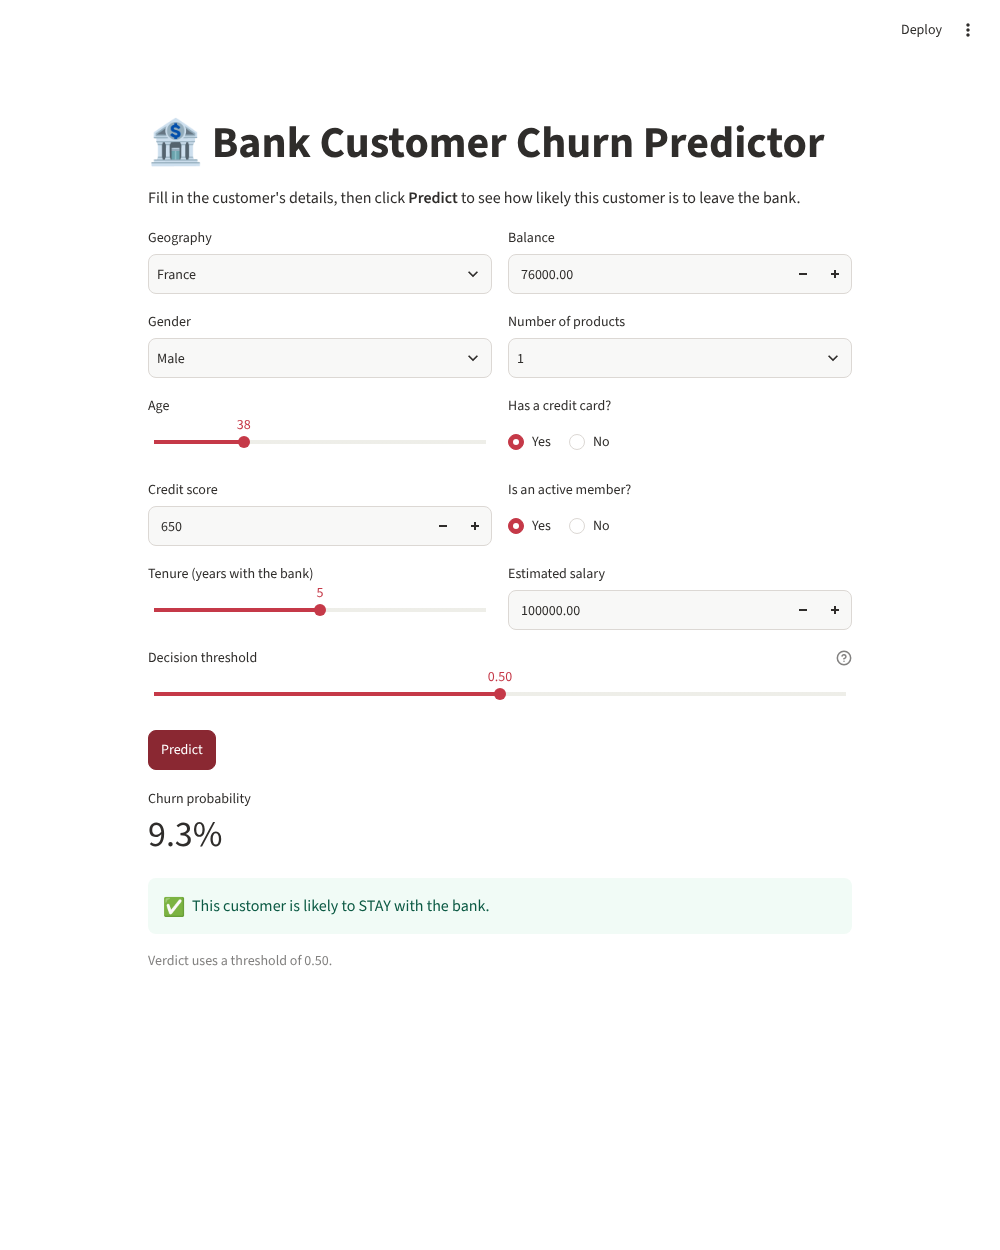

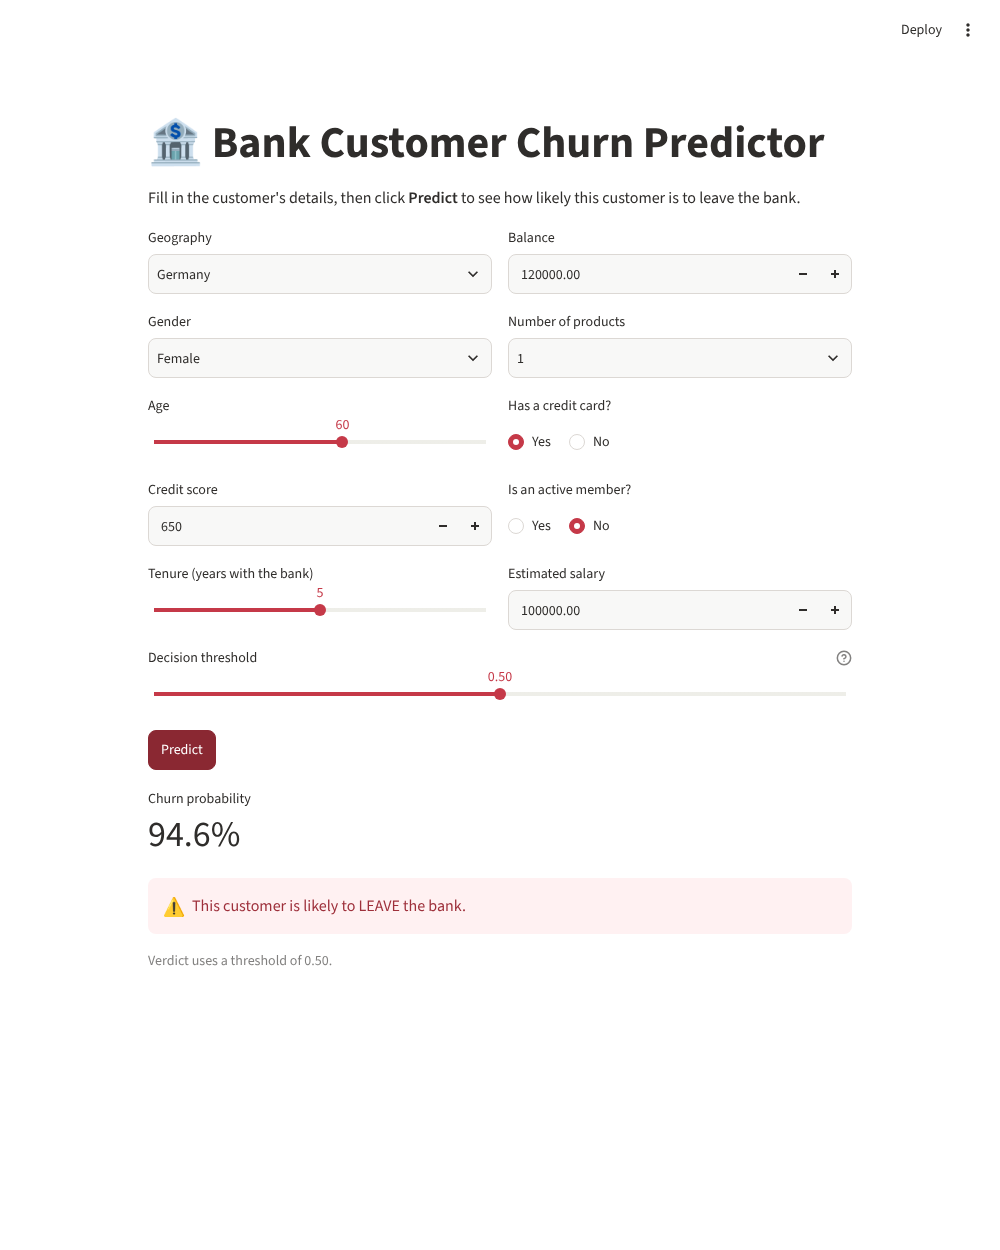

### Run the Streamlit app from Colab
Streamlit normally runs on your own laptop (`streamlit run app.py`). In Colab you can still open it by running the cell below: it starts Streamlit in the background and makes a temporary public link with `localtunnel`. When the link page asks for a **password**, paste the IP address that the cell prints. The cell only works inside Google Colab, and it needs `app.py`, `model.keras` and `preprocessor.pkl` in the Colab folder (the cells above create them).

In [ ]:
# Run the Streamlit app from Google Colab (works only in Colab)
!pip install -q streamlit

import subprocess, time, urllib.request

# 1. start Streamlit in the background on port 8501
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"])
time.sleep(5)

# 2. localtunnel asks for a "password": it is this Colab machine's public IP address
print("Tunnel password (paste it on the page that opens):", urllib.request.urlopen("https://ipv4.icanhazip.com").read().decode().strip())

# 3. open a public link to the app (stop this cell to close the link)
!npx -y localtunnel --port 8501

**My understanding:** When someone clicks Predict, the app collects every value, builds a one-row table with the same column names as training (Yes/No become 1/0), sends it through the saved preprocessor, and gives it to the model, which returns a probability. The app shows it as a percentage and says "likely to LEAVE" if it is at or above the threshold (0.5), otherwise "likely to STAY". My two test customers gave 9.3% (STAY) and 94.6% (LEAVE), as the manual expects.

## Bonus challenges
**1. Dropout (rate 0.2 after each hidden layer) and 2. class_weight (class 1 counts 3x)**, trained with the same seed and settings as the original model:

In [13]:
# Bonus: does Dropout or class_weight change the result? (same data, same seed, same settings otherwise)
def build_model(dropout=0.0):
    stack = [keras.Input(shape=(n_features,)), layers.Dense(16, activation="relu")]
    if dropout > 0:
        stack.append(layers.Dropout(dropout))
    stack.append(layers.Dense(8, activation="relu"))
    if dropout > 0:
        stack.append(layers.Dropout(dropout))
    stack.append(layers.Dense(1, activation="sigmoid"))
    m = keras.Sequential(stack)
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return m

def train_and_score(name, dropout=0.0, class_weight=None):
    keras.utils.set_random_seed(SEED)
    m = build_model(dropout)
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    h = m.fit(X_train_p, y_train, validation_split=0.2, epochs=50, batch_size=32,
              callbacks=[stop], class_weight=class_weight, verbose=0)
    pred = (m.predict(X_test_p, verbose=0).ravel() >= 0.5).astype(int)
    rep = classification_report(y_test, pred, output_dict=True, zero_division=0)
    return {"experiment": name, "epochs": len(h.history["loss"]),
            "accuracy": round(accuracy_score(y_test, pred), 4),
            "class-1 precision": round(rep["1"]["precision"], 3),
            "class-1 recall": round(rep["1"]["recall"], 3),
            "class-1 f1": round(rep["1"]["f1-score"], 3)}

bonus = pd.DataFrame([
    train_and_score("Original model (as in Step 6)"),
    train_and_score("Dropout 0.2 after each hidden layer", dropout=0.2),
    train_and_score("class_weight: class 1 counts 3x", class_weight={0: 1, 1: 3}),
])
print("Original model reproduces the Step 7 accuracy:", bonus.loc[0, "accuracy"] == round(accuracy_score(y_test, y_pred), 4))
bonus

Original model reproduces the Step 7 accuracy: True


,experiment,epochs,accuracy,class-1 precision,class-1 recall,class-1 f1
0,Original model (as in Step 6),50,0.8595,0.742,0.474,0.579
1,Dropout 0.2 after each hidden layer,50,0.8590,0.799,0.410,0.542
2,class_weight: class 1 counts 3x,50,0.8120,0.527,0.732,0.613


**What I found:**
* **Dropout 0.2:** test accuracy hardly changed (85.95% to 85.90%), but class-1 recall went *down* (0.474 to 0.410) while precision went up (0.742 to 0.799). It did not help this small network.
* **class_weight 1:3:** class-1 recall jumped from 0.474 to 0.732, but accuracy fell from 85.95% to 81.20% and precision fell to 0.527 (more false alarms).
* **Which would a bank prefer?** My view: the class_weight model, if a retention offer is cheap compared with losing a customer, because it finds many more of the leavers. If every offer is expensive, the original model with fewer false alarms may be better. It depends on those costs, so accuracy alone is not the right way to choose.

**3. Threshold slider:** done in `app.py` (slider from 0.30 to 0.70, default 0.50).
**4. Deploy on Streamlit Community Cloud:** not done here, it needs my own Streamlit account. The `README.md` explains how to do it from the GitHub repo.

## Final summary
* **Test accuracy: 85.95%** (a lazy "always stays" model would get 79.6%) and **class-1 recall: 0.47** (precision 0.74), so the model misses more than half of the customers who leave.
* **What I would try next:** (1) handle the imbalance with `class_weight` or a lower threshold to raise recall (the bonus above shows recall 0.73 with `class_weight`); (2) train for longer or try a slightly bigger network, since the validation loss was still falling at epoch 50; (3) compare with simple models like Logistic Regression or Random Forest.